# LSTM + XGBoost Precipitation Forecasting (Prefinal)


1. XGBoost hyperparameters come from a random search plus a refinement pass instead of a
   hardcoded dict.
2. XGBoost uses `dart` (dropout) with `reg:quantileerror` at alpha 0.5 and an identity output.
3. Ensemble weights are inverse-RMSE.
4. A 7-day forecast is added alongside the 1-day one.


In [1]:
# the notebook expects the repo root (2619492.csv, models/) as the working directory
import os
from pathlib import Path

start = Path.cwd()
for cand in [start, *start.parents]:
    if (cand / "2619492.csv").exists() and (cand / "streamlit_dashboard").is_dir():
        os.chdir(cand)
        break
else:
    raise RuntimeError(f"could not find repo root starting from {start}")

print(f"working directory: {Path.cwd()}")

Working directory set to repo root: C:\Users\Dell\Desktop\Thesis


In [2]:
import math
import time
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox, skew, kurtosis, pearsonr
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    explained_variance_score,
    roc_auc_score,
)
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Input

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"xgboost {xgb.__version__}, tensorflow {tf.__version__}")

Imports ready. xgboost 3.4.1 | tensorflow 2.21.0


In [3]:
def boxcox1p(data):
    p1data = data + 1
    bcdata, bclambda = boxcox(p1data)
    return bcdata, bclambda


def inv_boxcox1p(bcdata, bclambda):
    return inv_boxcox(bcdata, bclambda) - 1


def split_sequences(series, window):
    """x[i] = series[i:i+window], y[i] = series[i+window]."""
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    # days at or near zero are skipped, a near-zero denominator would swamp the mean
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())


def compute_sample_weights(y_boxcox, lambda_value, floor=0.01):
    # weight by rain amount so the many zero days do not dominate the fit
    y_orig = inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value)
    y_orig = np.maximum(y_orig, 0.0)
    return np.sqrt(y_orig + floor)


def prediction_bias(y_true, y_pred):
    """Mean signed error, positive means over-prediction."""
    return float(np.mean(np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)))


def residual_statistics(y_true, y_pred):
    resid = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        'mean': float(np.mean(resid)),
        'std': float(np.std(resid)),
        'skew': float(skew(resid)),
        'kurtosis': float(kurtosis(resid)),
        'min': float(np.min(resid)),
        'max': float(np.max(resid)),
    }


def improvement_percentage(baseline_value, new_value):
    if baseline_value == 0:
        return float('nan')
    return float((baseline_value - new_value) / baseline_value * 100.0)


RAIN_INTENSITY_BINS = [-np.inf, 1e-9, 0.2, 0.5, np.inf]
RAIN_INTENSITY_LABELS = ['No Rain (0 in)', 'Light (0-0.2 in)',
                         'Moderate (0.2-0.5 in)', 'Heavy (>0.5 in)']


def rainfall_intensity_performance(y_true, y_pred):
    """RMSE/MAE/MAPE per intensity bucket."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    buckets = np.asarray(pd.cut(y_true, bins=RAIN_INTENSITY_BINS, labels=RAIN_INTENSITY_LABELS))
    rows = []
    for label in RAIN_INTENSITY_LABELS:
        mask = (buckets == label)
        n = int(mask.sum())
        if n == 0:
            rows.append({'Intensity': label, 'N': 0, 'RMSE': float('nan'),
                         'MAE': float('nan'), 'MAPE (%)': float('nan')})
            continue
        rmse_b = math.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
        mae_b = mean_absolute_error(y_true[mask], y_pred[mask])
        mape_b = float('nan') if label == 'No Rain (0 in)' else \
            safe_mape(y_true[mask], y_pred[mask], min_actual=1e-9)[0]
        rows.append({'Intensity': label, 'N': n, 'RMSE': rmse_b, 'MAE': mae_b, 'MAPE (%)': mape_b})
    return pd.DataFrame(rows)


def evaluate_all(y_true, y_pred, label):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape, mape_n = safe_mape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    corr, _ = pearsonr(y_true, y_pred)
    expl_var = explained_variance_score(y_true, y_pred)
    bias = prediction_bias(y_true, y_pred)
    resid_stats = residual_statistics(y_true, y_pred)
    result = {
        'label': label, 'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_n': mape_n,
        'r2': r2, 'pearson_r': float(corr), 'explained_variance': float(expl_var),
        'bias': bias, 'pred_sd': float(np.std(y_pred)), 'residual_stats': resid_stats,
    }
    print(f"\n{label} evaluation:")
    print(f"  RMSE:                {rmse:.4f}")
    print(f"  MAE:                 {mae:.4f}")
    print(f"  MAPE:                {mape:.2f}% (on {mape_n} days >= 0.1 in)")
    print(f"  R2:                  {r2:.4f}")
    print(f"  Pearson r:           {corr:.4f}")
    print(f"  Explained Variance:  {expl_var:.4f}")
    print(f"  Prediction Bias:     {bias:+.4f} in (pred - true)")
    print(f"  Prediction sd:       {np.std(y_pred):.4f} in")
    print(f"  Residual std/skew/kurtosis: {resid_stats['std']:.4f} / "
          f"{resid_stats['skew']:.4f} / {resid_stats['kurtosis']:.4f}")
    return result


def sha256_dir(path):
    """Hash every file under a directory so it can be checked for changes."""
    path = Path(path)
    if not path.is_dir():
        return {}
    out = {}
    for f in sorted(path.rglob('*')):
        if f.is_file():
            out[str(f.relative_to(path))] = hashlib.sha256(f.read_bytes()).hexdigest()[:16]
    return out


def inverse_rmse_weights(rmse_a, rmse_b):
    """w_i = (1/RMSE_i) / sum_j(1/RMSE_j), so the lower-error model gets more weight."""
    inv_a, inv_b = 1.0 / rmse_a, 1.0 / rmse_b
    total = inv_a + inv_b
    return inv_a / total, inv_b / total


def make_anchor_windows(series, window, horizon):
    """Per anchor: the preceding `window` values and the next `horizon` observed values."""
    xs, fut = [], []
    last = len(series) - window - horizon
    for i in range(last + 1):
        xs.append(series[i:i + window])
        fut.append(series[i + window:i + window + horizon])
    return np.array(xs), np.array(fut)


EVENT_THRESHOLDS = [0.0, 0.5, 2.0, 5.0]


def event_detection(y_true, y_pred, thresholds=EVENT_THRESHOLDS):
    # POD/FAR/CSI/HSS use the forecast's own threshold crossing, AUC is threshold-free
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rows = []
    for thr in thresholds:
        obs = y_true > thr
        fc = y_pred > thr
        a = int(np.sum(obs & fc))         # hits
        b = int(np.sum(~obs & fc))        # false alarms
        c = int(np.sum(obs & ~fc))        # misses
        d = int(np.sum(~obs & ~fc))       # correct negatives
        pod = a / (a + c) if (a + c) else float('nan')
        far = b / (a + b) if (a + b) else float('nan')
        csi = a / (a + b + c) if (a + b + c) else float('nan')
        denom = (a + c) * (c + d) + (a + b) * (b + d)
        hss = (2.0 * (a * d - b * c) / denom) if denom else float('nan')
        try:
            auc = roc_auc_score(obs.astype(int), y_pred) if obs.any() and (~obs).any() else float('nan')
        except ValueError:
            auc = float('nan')
        rows.append({'Threshold (in)': thr, 'N events': int(obs.sum()),
                     'hits': a, 'false alarms': b, 'misses': c,
                     'POD': pod, 'FAR': far, 'CSI': csi, 'HSS': hss, 'AUC': auc})
    return pd.DataFrame(rows)


print("helpers defined")

Utility functions defined.


In [4]:
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

DATA_CUTOFF = 9058              # train [0:9058], test [9058:]
TOTAL_DATA_LENGTH = 10988
WINDOW_SIZE = 70                # lookback, shared by LSTM and XGBoost
ENSEMBLE_VALIDATION_FRACTION = 0.08   # slice used to derive the ensemble weights
XGB_VAL_FRACTION = 0.12               # slice used for XGBoost early stopping
XGB_EARLY_STOPPING_ROUNDS = 60

# LSTM, identical to the static notebook
LSTM_UNITS_LAYER1 = 32
LSTM_UNITS_LAYER2 = 32
LSTM_DENSE_UNITS = 16
LSTM_DROPOUT = 0.5
LSTM_EPOCHS = 100
LSTM_BATCH_SIZE = 60
LSTM_LEARNING_RATE = 1e-7
LSTM_MOMENTUM = 0.9

# search space from REFACTORED 2.2 cell 7, minus huber_slope, which only affects
# reg:pseudohubererror and cannot change a quantile fit
XGB_PARAM_DISTRIBUTIONS = {
    'n_estimators':     [400, 500, 600, 800, 1000, 1200],
    'max_depth':        [2, 3, 4, 5, 6],
    'learning_rate':    [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
    'subsample':        [0.70, 0.75, 0.85, 0.90, 1.00],
    'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
    'min_child_weight': [1, 2, 3, 5, 6, 8],
    'gamma':            [0.0, 0.05, 0.1, 0.2, 0.5],
    'reg_alpha':        [0.0, 0.05, 0.1, 0.2, 0.3, 0.5],
    'reg_lambda':       [0.5, 1.0, 1.5, 2.0, 3.0, 5.0],
}
XGB_N_ITER_SEARCH = 40
XGB_N_ITER_REFINE = 30

# rate_drop has to stay above 0. At the default 0.0 dart does no dropout and is
# bit-identical to gbtree. rate_drop=0.3 with skip_drop=0 diverged on this data
# (test RMSE around 1.4e6), so a moderate rate with a non-zero skip_drop is what works.
XGB_FIT_STRATEGY = {
    'booster': 'dart',
    'tree_method': 'hist',
    'rate_drop': 0.1,
    'skip_drop': 0.5,
}
XGB_OBJECTIVE = {
    'objective': 'reg:quantileerror',
    'quantile_alpha': 0.5,
}
OUTPUT_TRANSFORM = 'identity'   # relu is a no-op here, predictions are already non-negative

# both off by default
QUANTILE_ALPHA_SEARCH = False    # adds quantile_alpha [0.5..0.9] to the search space
FEATURE_SET = 'lag_only'         # 'lag_rolling' adds rolling mean/std over 7 and 14 days

if QUANTILE_ALPHA_SEARCH:
    XGB_PARAM_DISTRIBUTIONS['quantile_alpha'] = [0.5, 0.6, 0.7, 0.8, 0.9]

HORIZON = 7

# reproduced baseline, LSTM only, same dataset / split / preprocessing
BASELINE_RMSE = 6.2009
BASELINE_MAE = 2.3244
BASELINE_MAPE = 81.10

# the static notebook's LSTM test RMSE. This notebook retrains the LSTM and Keras on
# CPU is not reproducible to the digit, so treat this as a tolerance, not an equality.
REFERENCE_LSTM_RMSE = 5.9586
LSTM_RMSE_TOLERANCE = 0.10

STATIC_DIR = Path("models") / "v2_static"              # read only
MODEL_DIR = Path("models") / "v2_prefinal"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("configuration")
print(f"  fit strategy : {XGB_FIT_STRATEGY}")
print(f"  objective    : {XGB_OBJECTIVE}")
print(f"  output       : {OUTPUT_TRANSFORM}")
print(f"  search       : {XGB_N_ITER_SEARCH} draws + {XGB_N_ITER_REFINE} refinement fits over "
      f"{len(XGB_PARAM_DISTRIBUTIONS)} parameters")
print(f"  horizon      : {HORIZON} days")
print(f"  feature set  : {FEATURE_SET}")
print(f"  writing to {MODEL_DIR}, reading only from {STATIC_DIR}")

Configuration set.
  Fit strategy : {'booster': 'dart', 'tree_method': 'hist', 'rate_drop': 0.1, 'skip_drop': 0.5}
  Objective    : {'objective': 'reg:quantileerror', 'quantile_alpha': 0.5}
  Output       : identity
  Search       : 40 draws + 30 refinement fits over 9 parameters
  Horizon      : 7 days
  Feature set  : lag_only
  Writing to models\v2_prefinal  |  reading (never writing) models\v2_static


In [5]:
# models/v2_static/ is what the Streamlit site loads, so hash it now and re-check at the end
STATIC_HASHES_ON_ENTRY = sha256_dir(STATIC_DIR)
print(f"hashed {len(STATIC_HASHES_ON_ENTRY)} files in {STATIC_DIR}:")
for name, digest in STATIC_HASHES_ON_ENTRY.items():
    print(f"  {name:24} {digest}")

Hashed 4 files in models\v2_static:
  lstm_model.keras         78494620b3a17611
  metadata.json            cfa8142a793e6221
  scaler.joblib            8112db204b646956
  xgboost_model.json       b601bbe8b1aaf3d2


In [6]:
# lambda is estimated on the training portion only, then applied to the whole series
csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"could not find training data, searched: {TRAIN_DATA_CANDIDATES}")

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
print(f"loaded {len(rainfall)} records from {csv_path}")

_, lam_value = boxcox1p(rainfall.PRCP.iloc[:DATA_CUTOFF])
inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)
print(f"box-cox lambda (fit on train only): {lam_value:.6f}")

# the LSTM needs a bounded scale for gradient descent, XGBoost is scale-invariant
# so it uses the box-cox values unscaled
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(inv_data[:DATA_CUTOFF].reshape(-1, 1))
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

# with lambda < 0 the inverse box-cox is only defined below -1/lambda, anything above
# that asymptote comes back NaN. The static notebook's pseudo-huber fit never got near
# it but a quantile objective can, so clip just under the bound and report the count.
BC_UPPER = -1.0 / lam_value
print(f"inverse-transform asymptote: box-cox values must stay below {BC_UPPER:.6f}")


def to_original(bc_values):
    """Inverse box-cox with asymptote clipping. Returns (values, n_clipped)."""
    bc = np.asarray(bc_values, dtype=float).reshape(-1)
    n_clipped = int(np.sum(bc >= BC_UPPER))
    bc = np.minimum(bc, BC_UPPER - 1e-9)
    return inv_boxcox1p(bc, lam_value), n_clipped


print(f"series length used for modeling: {len(lstm_series)}")

Loaded 11323 records from 2619492.csv
Box-Cox lambda (fit on train only): -1.438692


Inverse-transform asymptote: Box-Cox values must stay below 0.695076
Series length used for modeling: 10988


In [7]:
# split the raw series at DATA_CUTOFF first, then window each half on its own, so no
# lookback context is borrowed across the cutoff. The first WINDOW_SIZE days of the test
# period are used as context and never scored.
lstm_train_series = lstm_series[:DATA_CUTOFF]
lstm_test_series = lstm_series[DATA_CUTOFF:]
xgb_train_series = xgb_series[:DATA_CUTOFF]
xgb_test_series = xgb_series[DATA_CUTOFF:]

x_train, y_train = split_sequences(lstm_train_series, WINDOW_SIZE)
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_train = x_train.reshape(-1, WINDOW_SIZE, 1)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)

x_train_lag, y_train_lag = split_sequences(xgb_train_series, WINDOW_SIZE)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

print(f"LSTM    train/test: {x_train.shape} / {x_test.shape}")
print(f"XGBoost train/test: {x_train_lag.shape} / {x_test_lag.shape}")
assert len(x_test) == len(x_test_lag), "LSTM and XGBoost test sets must be the same length"

LSTM    train/test: (8988, 70, 1) / (1860, 70, 1)
XGBoost train/test: (8988, 70) / (1860, 70)


In [8]:
model = Sequential()
model.add(Input(shape=(WINDOW_SIZE, 1)))
model.add(LSTM(LSTM_UNITS_LAYER1, activation='tanh', return_sequences=True))
model.add(Dropout(LSTM_DROPOUT))
model.add(LSTM(LSTM_UNITS_LAYER2, activation='relu'))
model.add(Dropout(LSTM_DROPOUT))
model.add(Dense(LSTM_DENSE_UNITS, activation='relu'))
model.add(Dense(1, activation='relu'))

lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: LSTM_LEARNING_RATE * 10 ** (epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=LSTM_LEARNING_RATE, momentum=LSTM_MOMENTUM)
model.compile(loss=tf.keras.losses.Huber(), optimizer=optimizer, metrics=["mean_squared_error"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# validation_data=(x_train, y_train) is copied from the static notebook and the baseline
# study, so the "validation" set is the training set. Kept so the LSTM stays identical.
#
# Cached: training takes about 25 minutes on this CPU and the architecture is fixed for the
# whole project, so the weights and loss history are written to MODEL_DIR on the first run
# and loaded afterwards. Delete lstm_model.keras to force a fresh fit.
LSTM_CACHE = MODEL_DIR / 'lstm_model.keras'
HISTORY_CACHE = MODEL_DIR / 'lstm_history.json'
FORCE_LSTM_RETRAIN = False

if LSTM_CACHE.exists() and HISTORY_CACHE.exists() and not FORCE_LSTM_RETRAIN:
    model = tf.keras.models.load_model(LSTM_CACHE)
    history_dict = json.loads(HISTORY_CACHE.read_text())
    lstm_train_seconds = float(history_dict.pop('_train_seconds', float('nan')))
    print(f"loaded cached LSTM from {LSTM_CACHE} "
          f"({model.count_params():,} parameters), training skipped")
    print(f"  original training time: {lstm_train_seconds:.1f}s "
          f"({lstm_train_seconds/60:.1f} min)")
else:
    print("training LSTM (no cache found)")
    lstm_train_start = time.time()
    history = model.fit(
        x_train, y_train,
        epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH_SIZE, verbose=0,
        validation_data=(x_train, y_train), callbacks=[lr_schedule],
    )
    lstm_train_seconds = time.time() - lstm_train_start
    print(f"done in {lstm_train_seconds:.1f}s ({lstm_train_seconds/60:.1f} min)")
    model.save(LSTM_CACHE)
    history_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    history_dict['_train_seconds'] = lstm_train_seconds
    HISTORY_CACHE.write_text(json.dumps(history_dict))
    history_dict.pop('_train_seconds')
    print(f"cached to {LSTM_CACHE} and {HISTORY_CACHE}")

Loaded cached LSTM from models\v2_prefinal\lstm_model.keras (13,217 parameters) -- training skipped.
  Original training time: 1003.6s (16.7 min)


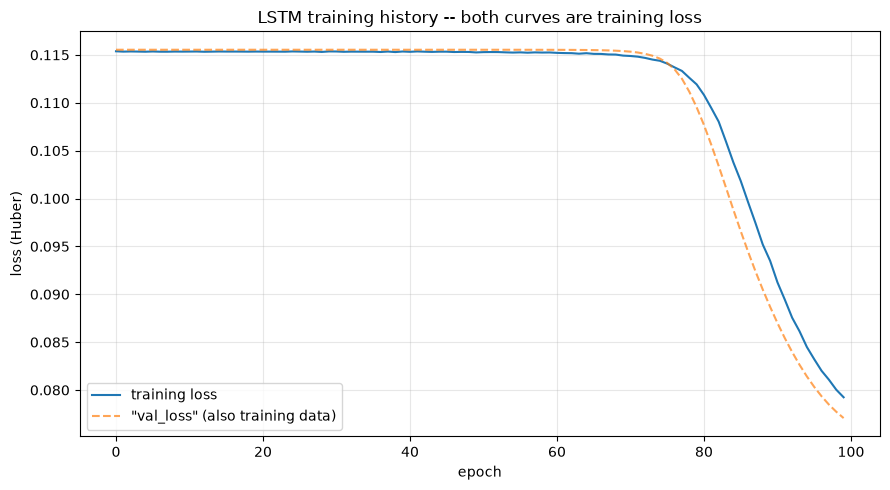

In [10]:
# both curves come from the training data, see the cell above
plt.figure(figsize=(9, 5))
plt.plot(history_dict['loss'], label='training loss')
plt.plot(history_dict['val_loss'], label='"val_loss" (also training data)',
         ls='--', alpha=0.7)
plt.xlabel('epoch')
plt.ylabel('loss (Huber)')
plt.title('LSTM training history, both curves are training loss')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / 'lstm_training_loss.png', dpi=130, bbox_inches='tight')
plt.show()

In [11]:
# both models share the same test targets day for day, so there is one y_test_orig
y_test_bc = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
y_test_orig, _ = to_original(y_test_bc)

y_test_lag_orig, _ = to_original(y_test_lag)
assert np.allclose(y_test_orig, y_test_lag_orig, atol=1e-6), \
    "LSTM and XGBoost targets must match"
print(f"scored test days: {len(y_test_orig)}")
print(f"observed mean {y_test_orig.mean():.3f} in, sd {y_test_orig.std():.3f} in, "
      f"max {y_test_orig.max():.1f} in")

Scored test days: 1860
Observed mean 2.261 in, sd 5.540 in, max 80.3 in


In [12]:
lstm_predict_start = time.time()
lstm_pred_scaled = model.predict(x_test, verbose=0)
lstm_predict_seconds = time.time() - lstm_predict_start

lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
lstm_pred_orig, _ = to_original(lstm_pred_bc)

lstm_eval = evaluate_all(y_test_orig, lstm_pred_orig, "LSTM (standalone)")
lstm_intensity = rainfall_intensity_performance(y_test_orig, lstm_pred_orig)
print("\nRainfall-Intensity Performance (LSTM):")
print(lstm_intensity.to_string(index=False))

# tolerance check, not equality, since the LSTM is retrained here
rmse_gap = abs(lstm_eval['rmse'] - REFERENCE_LSTM_RMSE)
print(f"\nLSTM RMSE {lstm_eval['rmse']:.4f} vs reference {REFERENCE_LSTM_RMSE}, "
      f"gap {rmse_gap:.4f} (tolerance {LSTM_RMSE_TOLERANCE})")
if rmse_gap <= LSTM_RMSE_TOLERANCE:
    print("within run-to-run training variance, as expected")
else:
    print("outside tolerance, check this before trusting the ensemble below")


LSTM (standalone) evaluation:
  RMSE:                5.9169
  MAE:                 2.2894
  MAPE:                82.01% (on 784 days >= 0.1 in)
  R2:                  -0.1408
  Pearson r:           -0.0105
  Explained Variance:  -0.0000
  Prediction Bias:     -2.0786 in (mean error, pred - true)
  Prediction sd:       0.0065 in
  Residual std/skew/kurtosis: 5.5398 / -4.5984 / 34.2689

Rainfall-Intensity Performance (LSTM):
            Intensity    N      RMSE      MAE  MAPE (%)
       No Rain (0 in) 1076  0.182289 0.182167       NaN
     Light (0-0.2 in)    0       NaN      NaN       NaN
Moderate (0.2-0.5 in)  184  0.217175 0.194049 48.223573
      Heavy (>0.5 in)  600 10.414214 6.710856 92.372994

LSTM RMSE 5.9169 vs reference 5.9586 -- gap 0.0417 (tolerance 0.1)
[OK] Within run-to-run training variance, as expected.


## XGBoost hyperparameters: searched


In [13]:
n_val = max(256, int(len(x_train_lag) * XGB_VAL_FRACTION))
x_tr, x_val = x_train_lag[:-n_val], x_train_lag[-n_val:]
y_tr, y_val = y_train_lag[:-n_val], y_train_lag[-n_val:]

sample_weight_tr = compute_sample_weights(y_tr, lam_value)
sample_weight_val = compute_sample_weights(y_val, lam_value)
y_val_orig, _ = to_original(y_val)

print(f"XGBoost fit / early-stopping split: {len(x_tr)} / {len(x_val)} "
      f"(last {XGB_VAL_FRACTION:.0%} of training, chronological)")

# these define the fit strategy, so they have to survive the searched config, otherwise a
# searched max_depth could overwrite one of them
STRATEGY_PINNED = ('booster', 'tree_method', 'rate_drop', 'skip_drop',
                   'grow_policy', 'max_leaves', 'updater', 'feature_selector')


def build_regressor(cfg):
    params = dict(
        eval_metric='rmse',          # mismatched with the quantile objective on purpose
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
    )
    params.update(XGB_FIT_STRATEGY)
    params.update(XGB_OBJECTIVE)
    pinned = {k: params[k] for k in STRATEGY_PINNED if k in params}
    params.update(dict(cfg))
    params.update(pinned)
    return xgb.XGBRegressor(**params)


def fit_candidate(cfg, x_fit=None, y_fit=None, sw_fit=None):
    """Fit one candidate and score validation RMSE in inches."""
    x_fit = x_tr if x_fit is None else x_fit
    y_fit = y_tr if y_fit is None else y_fit
    sw_fit = sample_weight_tr if sw_fit is None else sw_fit
    m = build_regressor(cfg)
    m.fit(x_fit, y_fit, sample_weight=sw_fit,
          eval_set=[(x_val, y_val)], sample_weight_eval_set=[sample_weight_val],
          verbose=False)
    pred, _ = to_original(m.predict(x_val))
    if not np.all(np.isfinite(pred)):
        return m, float('inf')
    return m, math.sqrt(mean_squared_error(y_val_orig, pred))


def search_hyperparameters(n_iter=None, n_refine=None, label=""):
    """Random search then a local refinement pass. Returns (best_cfg, best_rmse, n_fits)."""
    n_iter = XGB_N_ITER_SEARCH if n_iter is None else n_iter
    n_refine = XGB_N_ITER_REFINE if n_refine is None else n_refine

    sampled = list(ParameterSampler(XGB_PARAM_DISTRIBUTIONS, n_iter=n_iter,
                                    random_state=RANDOM_STATE))
    best_cfg, best_rmse, n_fits = None, np.inf, 0
    t_start = time.time()
    for i, cfg in enumerate(sampled, start=1):
        try:
            _, rmse = fit_candidate(cfg)
        except Exception:
            continue
        n_fits += 1
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, dict(cfg)
        if label and i % 5 == 0:
            el = time.time() - t_start
            print(f"    {label}: {i}/{n_iter} draws, best validation RMSE {best_rmse:.4f}"
                  f"  [{el/60:.1f} min elapsed, ~{el/i*(n_iter-i)/60:.1f} min left]",
                  flush=True)

    if best_cfg is None:
        raise RuntimeError("search found no viable configuration")

    refine_space = {
        'n_estimators':     [max(200, best_cfg['n_estimators'] - 300), best_cfg['n_estimators'],
                             min(2000, best_cfg['n_estimators'] + 300)],
        'max_depth':        [max(2, best_cfg['max_depth'] - 1), best_cfg['max_depth'],
                             min(8, best_cfg['max_depth'] + 1)],
        'learning_rate':    [max(0.005, best_cfg['learning_rate'] / 1.5), best_cfg['learning_rate'],
                             min(0.15, best_cfg['learning_rate'] * 1.5)],
        'subsample':        [max(0.50, best_cfg['subsample'] - 0.10), best_cfg['subsample'],
                             min(1.00, best_cfg['subsample'] + 0.10)],
        'colsample_bytree': [max(0.50, best_cfg['colsample_bytree'] - 0.10),
                             best_cfg['colsample_bytree'],
                             min(1.00, best_cfg['colsample_bytree'] + 0.10)],
        'min_child_weight': [max(1, best_cfg['min_child_weight'] - 2),
                             best_cfg['min_child_weight'], best_cfg['min_child_weight'] + 2],
        'gamma':            [best_cfg['gamma']],
        'reg_alpha':        [best_cfg['reg_alpha']],
        'reg_lambda':       [best_cfg['reg_lambda']],
    }
    if 'quantile_alpha' in best_cfg:
        refine_space['quantile_alpha'] = [best_cfg['quantile_alpha']]

    for cfg in ParameterSampler(refine_space, n_iter=n_refine, random_state=RANDOM_STATE):
        try:
            _, rmse = fit_candidate(cfg)
        except Exception:
            continue
        n_fits += 1
        if rmse < best_rmse:
            best_rmse, best_cfg = rmse, dict(cfg)

    return best_cfg, best_rmse, n_fits


print("search functions defined")

XGBoost fit / early-stopping split: 7910 / 1078 (last 12% of training, chronological)
Search functions defined.


In [14]:
# Cached the same way the LSTM is. The search takes about 55 minutes and is seeded, so a
# re-run reproduces the same selection, and the result is written out on the first run and
# reused afterwards. This is not the same as hardcoding: the values still come from the
# search, the space and the criterion are still declared above, and the cache records which
# run produced them. Set FORCE_SEARCH_RERUN = True, or delete the cache file, to search again.
SEARCH_CACHE = MODEL_DIR / 'search_result.json'
FORCE_SEARCH_RERUN = False

if SEARCH_CACHE.exists() and not FORCE_SEARCH_RERUN:
    cached = json.loads(SEARCH_CACHE.read_text())
    SEARCHED_PARAMS = cached['selected']
    searched_val_rmse = cached['validation_rmse']
    searched_n_fits = cached['n_fits']
    search_seconds = cached['search_seconds']
    print(f"loaded cached search result from {SEARCH_CACHE}, search skipped")
    print(f"  originally {searched_n_fits} fits in {search_seconds:.1f}s "
          f"({search_seconds/60:.1f} min)")
else:
    print(f"searching under {XGB_FIT_STRATEGY['booster']} / "
          f"{XGB_OBJECTIVE['objective']} (alpha={XGB_OBJECTIVE['quantile_alpha']})")
    search_start = time.time()
    SEARCHED_PARAMS, searched_val_rmse, searched_n_fits = search_hyperparameters(label="search")
    search_seconds = time.time() - search_start
    SEARCH_CACHE.write_text(json.dumps({
        'selected': SEARCHED_PARAMS,
        'validation_rmse': searched_val_rmse,
        'n_fits': searched_n_fits,
        'search_seconds': search_seconds,
        'space': XGB_PARAM_DISTRIBUTIONS,
        'fit_strategy': XGB_FIT_STRATEGY,
        'objective': XGB_OBJECTIVE,
        'criterion': 'RMSE in inches on the last 12% of training, chronological',
    }, indent=2, default=float))
    print(f"\nsearch complete: {searched_n_fits} fits in {search_seconds:.1f}s")
    print(f"cached to {SEARCH_CACHE}")

print(f"best validation RMSE (inches): {searched_val_rmse:.4f}")
print("\nselected hyperparameters:")
for k in sorted(SEARCHED_PARAMS):
    print(f"  {k:18} {SEARCHED_PARAMS[k]}")


def in_declared_space(value, candidates, tol=1e-9):
    # compare with a tolerance, 0.8 - 0.10 is 0.7000000000000001 and `in` would miss it
    return any(abs(value - c) < tol for c in candidates)


in_space = {k: in_declared_space(v, XGB_PARAM_DISTRIBUTIONS[k])
            for k, v in SEARCHED_PARAMS.items() if k in XGB_PARAM_DISTRIBUTIONS}
print(f"\n{sum(in_space.values())}/{len(in_space)} selected values lie in the declared space.")
for k, ok_flag in sorted(in_space.items()):
    if not ok_flag:
        print(f"  outside grid: {k}={SEARCHED_PARAMS[k]}")

Loaded cached search result from models\v2_prefinal\search_result.json -- search skipped.
  Originally 70 fits in 3221.1s (53.7 min)
Best validation RMSE (inches): 5.7227

Selected hyperparameters:
  colsample_bytree   0.7000000000000001
  gamma              0.0
  learning_rate      0.15
  max_depth          7
  min_child_weight   8
  n_estimators       1500
  reg_alpha          0.0
  reg_lambda         3.0
  subsample          0.75

6/9 selected values lie in the declared space.
  [outside grid] learning_rate=0.15
  [outside grid] max_depth=7
  [outside grid] n_estimators=1500


In [15]:
xgb_model = build_regressor(SEARCHED_PARAMS)
xgb_train_start = time.time()
xgb_model.fit(x_tr, y_tr,
              sample_weight=sample_weight_tr,
              eval_set=[(x_val, y_val)],
              sample_weight_eval_set=[sample_weight_val],
              verbose=False)
xgb_train_seconds = time.time() - xgb_train_start

best_it = getattr(xgb_model, 'best_iteration', None)
n_estimators_used = int(best_it + 1) if best_it is not None else SEARCHED_PARAMS['n_estimators']
print(f"XGBoost training complete in {xgb_train_seconds:.1f}s "
      f"({n_estimators_used} trees used of {SEARCHED_PARAMS['n_estimators']})")
if n_estimators_used >= SEARCHED_PARAMS['n_estimators']:
    print("early stopping never fired, the full tree budget was used, which is expected")
    print("here since eval_metric is RMSE while the objective minimises quantile loss")

# check dart is really doing dropout, with rate_drop=0.0 it is bit-identical to gbtree
# and the configuration would quietly not be the one it claims to be
probe_params = {k: v for k, v in SEARCHED_PARAMS.items() if k not in XGB_OBJECTIVE}
probe = xgb.XGBRegressor(booster='gbtree', tree_method='hist', eval_metric='rmse',
                         random_state=RANDOM_STATE, n_jobs=-1, verbosity=0,
                         early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
                         **XGB_OBJECTIVE, **probe_params)
probe.fit(x_tr, y_tr, sample_weight=sample_weight_tr,
          eval_set=[(x_val, y_val)], sample_weight_eval_set=[sample_weight_val], verbose=False)
preds_match = np.allclose(xgb_model.predict(x_test_lag), probe.predict(x_test_lag))
print(f"\ndart vs gbtree on identical hyperparameters, predictions identical? {preds_match}")
print("dart is doing dropout" if not preds_match else
      "dart collapsed onto gbtree, rate_drop was lost")

XGBoost training complete in 224.8s (1499 trees used of 1500)



dart vs gbtree on identical hyperparameters -- predictions identical? False
[OK] dart is doing dropout.


In [16]:
xgb_predict_start = time.time()
xgb_pred_bc = xgb_model.predict(x_test_lag)
xgb_predict_seconds = time.time() - xgb_predict_start

xgb_pred_orig, n_clipped_test = to_original(xgb_pred_bc)
if OUTPUT_TRANSFORM == 'relu':
    xgb_pred_orig = np.maximum(xgb_pred_orig, 0.0)
print(f"predictions clipped at the box-cox asymptote: {n_clipped_test} of {len(xgb_pred_bc)}")

xgb_eval = evaluate_all(y_test_orig, xgb_pred_orig, "XGBoost (standalone)")
xgb_intensity = rainfall_intensity_performance(y_test_orig, xgb_pred_orig)
print("\nRainfall-Intensity Performance (XGBoost):")
print(xgb_intensity.to_string(index=False))

Predictions clipped at the Box-Cox asymptote: 0 of 1860

XGBoost (standalone) evaluation:
  RMSE:                5.7217
  MAE:                 3.7435
  MAPE:                251.29% (on 784 days >= 0.1 in)
  R2:                  -0.0668
  Pearson r:           -0.0368
  Explained Variance:  -0.0447
  Prediction Bias:     +0.8228 in (mean error, pred - true)
  Prediction sd:       0.9851 in
  Residual std/skew/kurtosis: 5.6622 / -4.3934 / 32.0508

Rainfall-Intensity Performance (XGBoost):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 3.267656 3.106812        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 2.881617 2.707207 771.594008
      Heavy (>0.5 in)  600 8.932634 5.203075  91.725087


In [17]:
# inverse-RMSE weighting, same as the static notebook, which already derives the weights
# from validation RMSE instead of hardcoding them
n_ens_val = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
x_ens_val_lstm = x_train[-n_ens_val:]
x_ens_val_xgb = x_train_lag[-n_ens_val:]
y_ens_val_lag = y_train_lag[-n_ens_val:]

lstm_val_pred_scaled = model.predict(x_ens_val_lstm, verbose=0).flatten()
lstm_val_pred_bc = scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0]
lstm_val_pred_orig, _ = to_original(lstm_val_pred_bc)

xgb_val_pred_orig, _ = to_original(xgb_model.predict(x_ens_val_xgb))
y_ens_val_orig, _ = to_original(y_ens_val_lag)

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
rmse_xgb_val = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))
w_lstm, w_xgb = inverse_rmse_weights(rmse_lstm_val, rmse_xgb_val)

print(f"ensemble-weight slice: {n_ens_val} days (last {ENSEMBLE_VALIDATION_FRACTION:.0%} of training)")
print(f"validation RMSE, LSTM: {rmse_lstm_val:.4f}, XGBoost: {rmse_xgb_val:.4f}")
print(f"inverse-RMSE weights, LSTM: {w_lstm:.4f}, XGBoost: {w_xgb:.4f}")
print(f"  (same as w_lstm = RMSE_xgb/(RMSE_lstm+RMSE_xgb) = "
      f"{rmse_xgb_val/(rmse_lstm_val+rmse_xgb_val):.4f})")

ensemble_pred_orig = w_lstm * lstm_pred_orig + w_xgb * xgb_pred_orig
ensemble_eval = evaluate_all(y_test_orig, ensemble_pred_orig,
                             "Ensemble (Inverse-RMSE weighting)")
ensemble_intensity = rainfall_intensity_performance(y_test_orig, ensemble_pred_orig)
print("\nRainfall-Intensity Performance (Ensemble):")
print(ensemble_intensity.to_string(index=False))

Ensemble-weight slice: 719 days (last 8% of training)
Validation RMSE -- LSTM: 6.2184, XGBoost: 6.0032
Inverse-RMSE weights -- LSTM: 0.4912, XGBoost: 0.5088
  (equivalently w_lstm = RMSE_xgb/(RMSE_lstm+RMSE_xgb) = 0.4912)

Ensemble (Inverse-RMSE weighting) evaluation:
  RMSE:                5.6131
  MAE:                 2.8894
  MAPE:                136.20% (on 784 days >= 0.1 in)
  R2:                  -0.0267
  Pearson r:           -0.0370
  Explained Variance:  -0.0148
  Prediction Bias:     -0.6024 in (mean error, pred - true)
  Prediction sd:       0.5003 in
  Residual std/skew/kurtosis: 5.5806 / -4.5466 / 33.6355

Rainfall-Intensity Performance (Ensemble):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 1.747632 1.670245        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 1.380429 1.282129 368.904902
      Heavy (>0.5 in)  600 9.571223 5.568508  64.842503


In [18]:
def improvement_row(evaluation):
    return {
        'RMSE improvement (%)': improvement_percentage(BASELINE_RMSE, evaluation['rmse']),
        'MAE improvement (%)': improvement_percentage(BASELINE_MAE, evaluation['mae']),
        'MAPE improvement (%)': improvement_percentage(BASELINE_MAPE, evaluation['mape']),
    }


comparison_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    row = {
        'Model': evaluation['label'],
        'RMSE': evaluation['rmse'],
        'MAE': evaluation['mae'],
        'MAPE (%)': evaluation['mape'],
        'R2': evaluation['r2'],
        'Pearson r': evaluation['pearson_r'],
        'Explained Variance': evaluation['explained_variance'],
        'Bias (mean error)': evaluation['bias'],
        'pred sd': evaluation['pred_sd'],
    }
    row.update(improvement_row(evaluation))
    comparison_rows.append(row)

df_comparison = pd.DataFrame(comparison_rows)
print(f"baseline reference (reproduced): RMSE={BASELINE_RMSE}, MAE={BASELINE_MAE}, "
      f"MAPE={BASELINE_MAPE}%\n")
print(df_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Baseline reference (reproduced): RMSE=6.2009, MAE=2.3244, MAPE=81.1%

                            Model   RMSE    MAE  MAPE (%)      R2  Pearson r  Explained Variance  Bias (mean error)  pred sd  RMSE improvement (%)  MAE improvement (%)  MAPE improvement (%)
                LSTM (standalone) 5.9169 2.2894   82.0114 -0.1408    -0.0105             -0.0000            -2.0786   0.0065                4.5801               1.5070               -1.1238
             XGBoost (standalone) 5.7217 3.7435  251.2862 -0.0668    -0.0368             -0.0447             0.8228   0.9851                7.7281             -61.0521             -209.8473
Ensemble (Inverse-RMSE weighting) 5.6131 2.8894  136.2041 -0.0267    -0.0370             -0.0148            -0.6024   0.5003                9.4799             -24.3054              -67.9459


In [19]:
intensity_tables = {'LSTM': lstm_intensity, 'XGBoost': xgb_intensity,
                    'Ensemble': ensemble_intensity}
for name, table in intensity_tables.items():
    print(f"\n{name}:")
    print(table.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


LSTM:
            Intensity    N    RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076  0.1823 0.1822       NaN
     Light (0-0.2 in)    0     NaN    NaN       NaN
Moderate (0.2-0.5 in)  184  0.2172 0.1940   48.2236
      Heavy (>0.5 in)  600 10.4142 6.7109   92.3730

XGBoost:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 3.2677 3.1068       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 2.8816 2.7072  771.5940
      Heavy (>0.5 in)  600 8.9326 5.2031   91.7251

Ensemble:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 1.7476 1.6702       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 1.3804 1.2821  368.9049
      Heavy (>0.5 in)  600 9.5712 5.5685   64.8425


                            Model    mean    std    skew  kurtosis      min    max
                LSTM (standalone) -2.0786 5.5398 -4.5984   34.2689 -80.1213 0.1934
             XGBoost (standalone)  0.8228 5.6622 -4.3934   32.0508 -77.3614 7.6145
Ensemble (Inverse-RMSE weighting) -0.6024 5.5806 -4.5466   33.6355 -78.7170 3.9574


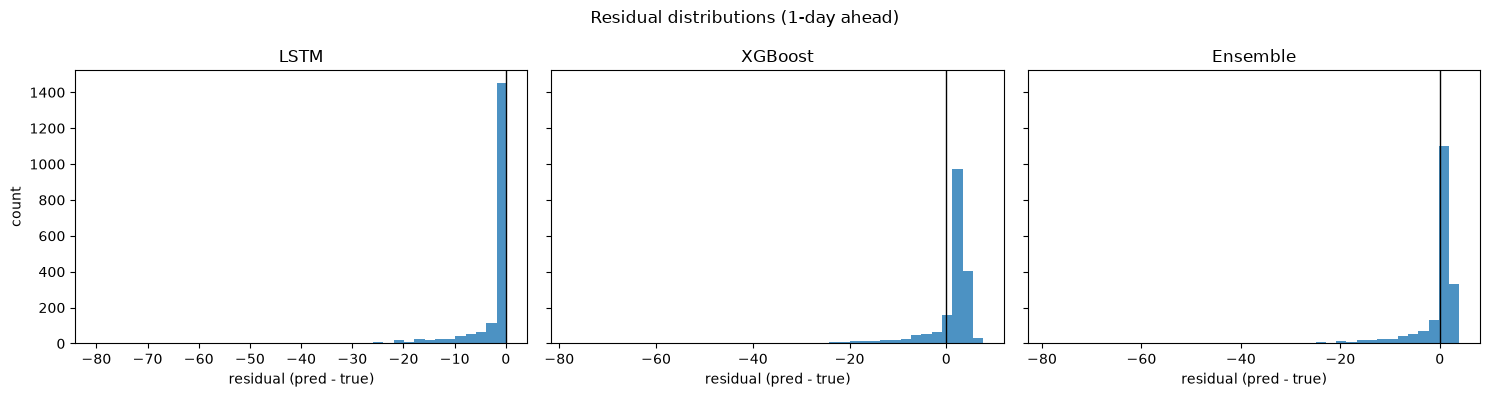

In [20]:
residual_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    row = {'Model': evaluation['label']}
    row.update(evaluation['residual_stats'])
    residual_rows.append(row)

df_residuals = pd.DataFrame(residual_rows)
print(df_residuals.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, pred) in zip(axes, [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig),
                                   ('Ensemble', ensemble_pred_orig)]):
    resid = np.asarray(pred) - np.asarray(y_test_orig)
    ax.hist(resid, bins=40, alpha=0.8)
    ax.axvline(0, color='k', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('residual (pred - true)')
axes[0].set_ylabel('count')
plt.suptitle('Residual distributions (1-day ahead)')
plt.tight_layout()
plt.savefig(MODEL_DIR / 'residuals_1day.png', dpi=130, bbox_inches='tight')
plt.show()

## Event detection

RMSE, MAE and MAPE score the magnitude of a forecast. They do not say whether it orders days
correctly, which is what a warning product needs, so the same predictions are scored again as an
event detector.

AUC is the threshold-free measure: 0.5 is chance, and it is invariant to any monotone rescaling of
the forecast, so shifting the forecast level cannot inflate it. POD, FAR, CSI and HSS use the
forecast's own crossing of each threshold, so they look poor for a forecast with a narrow range.
That is informative rather than a problem with the metric.

In [21]:
event_tables = {}
for name, pred in [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig),
                   ('Ensemble', ensemble_pred_orig)]:
    tbl = event_detection(y_test_orig, pred)
    event_tables[name] = tbl
    print(f"\n{name}:")
    print(tbl.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

print("\nAUC comparison (threshold-free, 0.5 = chance):")
auc_cmp = pd.DataFrame({name: t.set_index('Threshold (in)')['AUC']
                        for name, t in event_tables.items()})
print(auc_cmp.to_string(float_format=lambda x: f'{x:.4f}'))


LSTM:
 Threshold (in)  N events  hits  false alarms  misses    POD    FAR    CSI    HSS    AUC
         0.0000       784   784          1076       0 1.0000 0.5785 0.4215 0.0000 0.5623
         0.5000       600     0             0     600 0.0000    NaN 0.0000 0.0000 0.5434
         2.0000       392     0             0     392 0.0000    NaN 0.0000 0.0000 0.5075
         5.0000       263     0             0     263 0.0000    NaN 0.0000 0.0000 0.4833

XGBoost:
 Threshold (in)  N events  hits  false alarms  misses    POD    FAR    CSI    HSS    AUC
         0.0000       784   784          1076       0 1.0000 0.5785 0.4215 0.0000 0.4886
         0.5000       600   600          1260       0 1.0000 0.6774 0.3226 0.0000 0.4874
         2.0000       392   350          1292      42 0.8929 0.7868 0.2078 0.0059 0.4992
         5.0000       263    14            72     249 0.0532 0.8372 0.0418 0.0113 0.4971

Ensemble:
 Threshold (in)  N events  hits  false alarms  misses    POD    FAR    CSI    HSS 

## 7-day forecast

Everything above is 1-day ahead. This section checks whether the forecast changes over a longer lead.

Each anchor holds the 70 days before it plus the next 7 observed days. Two methods are run:

- Recursive: each prediction is fed back into the window. Same as the old 7-day notebook, so error
  accumulates.
- Direct: seven separate XGBoost models, model h trained on `y[t+h]`. No feedback.

The LSTM is recursive in both, since its architecture is fixed for this project.

Weights are re-derived at each lead day from that lead's validation RMSE. The baselines are
persistence and the train mean, because a flat forecast can otherwise pass for a stable one.

Anchor windowing uses up 7 trailing days, so this table covers fewer days than the 1-day result.

In [22]:
lstm_anchor_x, lstm_anchor_fut = make_anchor_windows(lstm_test_series, WINDOW_SIZE, HORIZON)
xgb_anchor_x, xgb_anchor_fut = make_anchor_windows(xgb_test_series, WINDOW_SIZE, HORIZON)
n_anchors = xgb_anchor_x.shape[0]

true_future_orig = np.zeros((n_anchors, HORIZON))
for h in range(HORIZON):
    true_future_orig[:, h], _ = to_original(xgb_anchor_fut[:, h])

print(f"test anchors: {n_anchors} (vs {len(y_test_orig)} scored days in the 1-day path)")
print(f"each anchor carries a {WINDOW_SIZE}-day lookback and {HORIZON} observed future days")

# training anchors, used for the per-lead ensemble weights and the direct models. The last
# XGB_VAL_FRACTION is the validation slice, chronological.
lstm_tr_anchor_x, lstm_tr_anchor_fut = make_anchor_windows(lstm_train_series, WINDOW_SIZE, HORIZON)
xgb_tr_anchor_x, xgb_tr_anchor_fut = make_anchor_windows(xgb_train_series, WINDOW_SIZE, HORIZON)

n_anchor_val = max(256, int(len(xgb_tr_anchor_x) * XGB_VAL_FRACTION))
xgb_fit_x, xgb_vl_x = xgb_tr_anchor_x[:-n_anchor_val], xgb_tr_anchor_x[-n_anchor_val:]
xgb_fit_fut, xgb_vl_fut = xgb_tr_anchor_fut[:-n_anchor_val], xgb_tr_anchor_fut[-n_anchor_val:]
lstm_vl_x = lstm_tr_anchor_x[-n_anchor_val:]

vl_true_orig = np.zeros((n_anchor_val, HORIZON))
for h in range(HORIZON):
    vl_true_orig[:, h], _ = to_original(xgb_vl_fut[:, h])

print(f"training anchors: {len(xgb_tr_anchor_x)} "
      f"({len(xgb_fit_x)} fit / {n_anchor_val} validation)")

Test anchors: 1854 (vs 1860 scored days in the 1-day path)
Each anchor carries a 70-day lookback and 7 observed future days.


Training anchors: 8982 (7905 fit / 1077 validation)


In [23]:
# the LSTM works in scaled box-cox space and XGBoost in unscaled box-cox space, each
# matching how it was trained
def recursive_rollout(lstm_windows, xgb_windows, horizon):
    """Returns (lstm_pred_orig_by_h, xgb_pred_orig_by_h), each (n, horizon)."""
    lw = lstm_windows.copy()
    xw = xgb_windows.copy()
    n = lw.shape[0]
    lstm_out = np.zeros((n, horizon))
    xgb_out = np.zeros((n, horizon))
    for h in range(horizon):
        step_l = model.predict(lw.reshape(-1, WINDOW_SIZE, 1), verbose=0).flatten()
        lstm_out[:, h], _ = to_original(scaler.inverse_transform(step_l.reshape(-1, 1))[:, 0])
        lw = np.concatenate([lw[:, 1:], step_l.reshape(-1, 1)], axis=1)

        step_x = xgb_model.predict(xw)
        xgb_out[:, h], _ = to_original(step_x)
        xw = np.concatenate([xw[:, 1:], step_x.reshape(-1, 1)], axis=1)
    return lstm_out, xgb_out


print("recursive rollout on the test anchors")
t0 = time.time()
lstm_rec_test, xgb_rec_test = recursive_rollout(lstm_anchor_x, xgb_anchor_x, HORIZON)
print(f"  done in {time.time() - t0:.1f}s")

print("recursive rollout on the validation anchors, for the per-lead weights")
t0 = time.time()
lstm_rec_val, xgb_rec_val = recursive_rollout(lstm_vl_x, xgb_vl_x, HORIZON)
print(f"  done in {time.time() - t0:.1f}s")

Recursive rollout on the test anchors...


  done in 10.3s
Recursive rollout on the validation anchors (for the per-lead weights)...


  done in 6.8s


In [24]:
# one model per lead day, trained on y[t+h], so no feedback and no error accumulation
xgb_dir_test = np.zeros((n_anchors, HORIZON))
xgb_dir_val = np.zeros((n_anchor_val, HORIZON))
direct_models = {}

print("training direct-per-horizon models")
t0 = time.time()
for h in range(HORIZON):
    y_fit_h = xgb_fit_fut[:, h]
    y_vl_h = xgb_vl_fut[:, h]
    sw_h = compute_sample_weights(y_fit_h, lam_value)
    sw_vl_h = compute_sample_weights(y_vl_h, lam_value)

    m = build_regressor(SEARCHED_PARAMS)
    m.fit(xgb_fit_x, y_fit_h, sample_weight=sw_h,
          eval_set=[(xgb_vl_x, y_vl_h)], sample_weight_eval_set=[sw_vl_h], verbose=False)
    direct_models[h + 1] = m

    xgb_dir_test[:, h], _ = to_original(m.predict(xgb_anchor_x))
    xgb_dir_val[:, h], _ = to_original(m.predict(xgb_vl_x))
    bi = getattr(m, 'best_iteration', None)
    print(f"  lead {h+1}: {int(bi + 1) if bi is not None else SEARCHED_PARAMS['n_estimators']} trees")
direct_seconds = time.time() - t0
print(f"seven direct models trained in {direct_seconds:.1f}s")

Training direct-per-horizon models...


  lead 1: 1486 trees


  lead 2: 1499 trees


  lead 3: 1485 trees


  lead 4: 1499 trees


  lead 5: 1499 trees


  lead 6: 1498 trees


  lead 7: 1499 trees
Seven direct models trained in 1417.0s


In [25]:
# persistence carries the last observed value forward, the train-mean constant is the same
# number every day
last_known_orig, _ = to_original(xgb_anchor_x[:, -1])
train_mean_orig = float(np.mean(to_original(xgb_train_series)[0]))

rows = []
ens_by_method = {'recursive': np.zeros((n_anchors, HORIZON)),
                 'direct': np.zeros((n_anchors, HORIZON))}
weights_by_method = {'recursive': [], 'direct': []}

# weights are re-derived at each lead from that lead's validation RMSE, per method
for h in range(HORIZON):
    yt = true_future_orig[:, h]
    yv = vl_true_orig[:, h]

    rmse_l_val = math.sqrt(mean_squared_error(yv, lstm_rec_val[:, h]))

    for method, xgb_test_h, xgb_val_h in [
        ('recursive', xgb_rec_test[:, h], xgb_rec_val[:, h]),
        ('direct',    xgb_dir_test[:, h], xgb_dir_val[:, h]),
    ]:
        rmse_x_val = math.sqrt(mean_squared_error(yv, xgb_val_h))
        wl, wx = inverse_rmse_weights(rmse_l_val, rmse_x_val)
        ens = wl * lstm_rec_test[:, h] + wx * xgb_test_h
        ens_by_method[method][:, h] = ens
        weights_by_method[method].append((wl, wx))

        mape_e, _ = safe_mape(yt, ens)
        rows.append({
            'Lead day': h + 1, 'XGB method': method,
            'w_lstm': wl, 'w_xgb': wx,
            'LSTM RMSE': math.sqrt(mean_squared_error(yt, lstm_rec_test[:, h])),
            'XGB RMSE': math.sqrt(mean_squared_error(yt, xgb_test_h)),
            'ENS RMSE': math.sqrt(mean_squared_error(yt, ens)),
            'ENS MAE': mean_absolute_error(yt, ens),
            'ENS MAPE (%)': mape_e,
            'ENS R2': r2_score(yt, ens),
            'ENS bias': prediction_bias(yt, ens),
            'ENS pred sd': float(np.std(ens)),
            'XGB pred sd': float(np.std(xgb_test_h)),
            'Persistence RMSE': math.sqrt(mean_squared_error(yt, last_known_orig)),
            'Train-mean RMSE': math.sqrt(mean_squared_error(
                yt, np.full_like(yt, train_mean_orig))),
        })

df_lead = pd.DataFrame(rows)
df_lead.to_csv(MODEL_DIR / 'per_lead_results.csv', index=False)

for method in ('recursive', 'direct'):
    print(f"\nXGBoost {method}")
    sub = df_lead[df_lead['XGB method'] == method].drop(columns=['XGB method'])
    print(sub.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

print(f"\nsaved {MODEL_DIR / 'per_lead_results.csv'}")
print(f"train-mean constant: {train_mean_orig:.4f} in")


=== XGBoost recursive ===
 Lead day  w_lstm  w_xgb  LSTM RMSE  XGB RMSE  ENS RMSE  ENS MAE  ENS MAPE (%)  ENS R2  ENS bias  ENS pred sd  XGB pred sd  Persistence RMSE  Train-mean RMSE
        1  0.4926 0.5074     5.9264    5.7300    5.6222   2.8938      135.9431 -0.0271   -0.6109       0.4990       0.9850            7.4948           5.5539
        2  0.4941 0.5059     5.9266    5.7480    5.6210   2.9106      137.6462 -0.0267   -0.5821       0.5202       1.0301            7.9248           5.5537
        3  0.4902 0.5098     5.9266    5.6567    5.6251   2.8169      126.3206 -0.0282   -0.7518       0.4288       0.8427            7.7629           5.5537
        4  0.4901 0.5099     5.9267    5.6404    5.6248   2.7995      124.4591 -0.0281   -0.7809       0.4083       0.8019            7.8693           5.5537
        5  0.4900 0.5100     5.9268    5.6394    5.6283   2.7951      123.5004 -0.0294   -0.7946       0.3929       0.7717            7.9101           5.5537
        6  0.4905 0.5095 

In [26]:
print(f"observed target sd at lead 1: {true_future_orig[:, 0].std():.4f} in\n")
for method in ('recursive', 'direct'):
    sub = df_lead[df_lead['XGB method'] == method]
    r1, r7 = sub['ENS RMSE'].iloc[0], sub['ENS RMSE'].iloc[-1]
    s1, s7 = sub['ENS pred sd'].iloc[0], sub['ENS pred sd'].iloc[-1]
    print(f"{method:10}  ENS RMSE lead1 {r1:.4f} -> lead7 {r7:.4f}  "
          f"({(r7-r1)/r1*100:+.2f}%)   pred sd {s1:.4f} -> {s7:.4f}")

print("\nhow to read these numbers:")
print("  error that barely moves across leads is not stability if the predictive spread is")
print("  near zero, it means the forecast settled on a constant and stopped responding, so")
print("  compare 'ENS pred sd' against the observed sd above")
print("  'direct' shows how much harder each horizon genuinely is, since it never feeds")
print("  predictions back, 'recursive' adds error accumulation on top of that")
print("  if neither beats 'Persistence RMSE' at a lead then the model adds nothing there")

beat = df_lead.assign(beats_persistence=df_lead['ENS RMSE'] < df_lead['Persistence RMSE'])
print("\nbeats persistence?")
print(beat.pivot_table(index='Lead day', columns='XGB method',
                       values='beats_persistence').to_string())

Observed target sd at lead 1: 5.5476 in

recursive   ENS RMSE lead1 5.6222 -> lead7 5.6270  (+0.09%)   pred sd 0.4990 -> 0.4244
direct      ENS RMSE lead1 5.6234 -> lead7 5.6170  (-0.11%)   pred sd 0.5315 -> 0.5331

Reading these numbers:
  * Error that barely moves across leads is NOT stability if the predictive spread is
    near zero -- it means the forecast settled on a constant and stopped responding.
    Compare 'ENS pred sd' against the observed sd above.
  * 'direct' isolates how much harder each horizon genuinely is, since it never feeds
    predictions back. 'recursive' adds error accumulation on top of that.
  * If neither beats 'Persistence RMSE' at a lead, the model adds nothing at that lead.

Beats persistence?
XGB method  direct  recursive
Lead day                     
1              1.0        1.0
2              1.0        1.0
3              1.0        1.0
4              1.0        1.0
5              1.0        1.0
6              1.0        1.0
7              1.0       

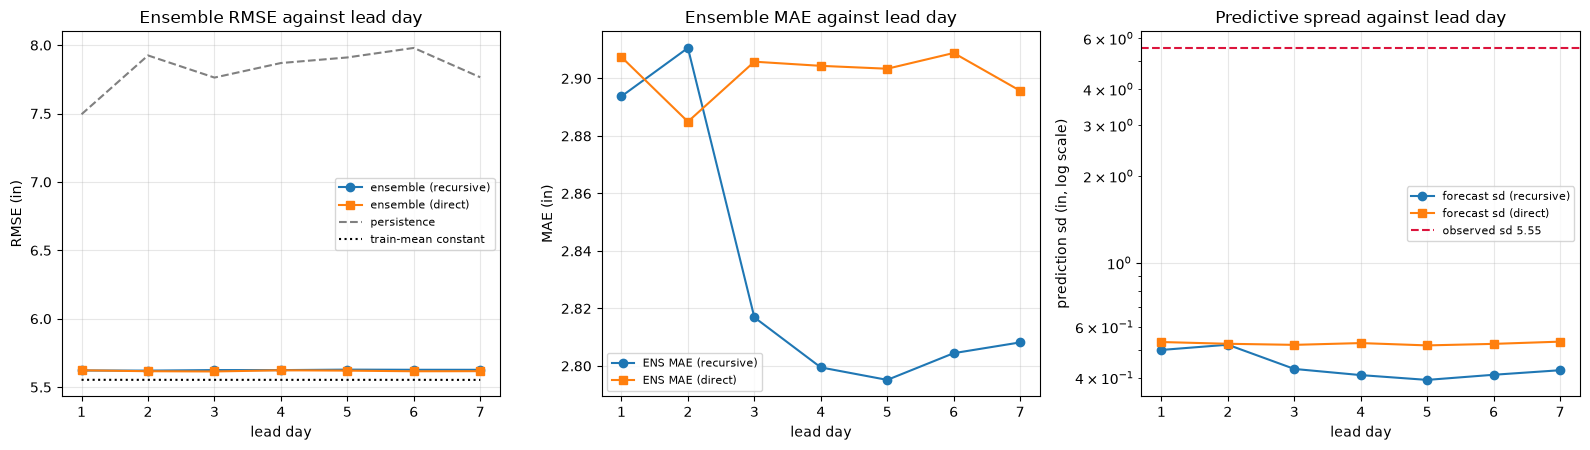

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
leads = range(1, HORIZON + 1)

ax = axes[0]
for method, mk in [('recursive', 'o'), ('direct', 's')]:
    sub = df_lead[df_lead['XGB method'] == method]
    ax.plot(leads, sub['ENS RMSE'], marker=mk, label=f'ensemble ({method})')
sub = df_lead[df_lead['XGB method'] == 'recursive']
ax.plot(leads, sub['Persistence RMSE'], ls='--', color='gray', label='persistence')
ax.plot(leads, sub['Train-mean RMSE'], ls=':', color='black', label='train-mean constant')
ax.set_xlabel('lead day'); ax.set_ylabel('RMSE (in)')
ax.set_title('Ensemble RMSE against lead day'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
for method, mk in [('recursive', 'o'), ('direct', 's')]:
    sub = df_lead[df_lead['XGB method'] == method]
    ax.plot(leads, sub['ENS MAE'], marker=mk, label=f'ENS MAE ({method})')
ax.set_xlabel('lead day'); ax.set_ylabel('MAE (in)')
ax.set_title('Ensemble MAE against lead day'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[2]
for method, mk in [('recursive', 'o'), ('direct', 's')]:
    sub = df_lead[df_lead['XGB method'] == method]
    ax.plot(leads, sub['ENS pred sd'], marker=mk, label=f'forecast sd ({method})')
ax.axhline(true_future_orig[:, 0].std(), ls='--', color='crimson',
           label=f'observed sd {true_future_orig[:, 0].std():.2f}')
ax.set_yscale('log')
ax.set_xlabel('lead day'); ax.set_ylabel('prediction sd (in, log scale)')
ax.set_title('Predictive spread against lead day'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'error_vs_lead_day.png', dpi=130, bbox_inches='tight')
plt.show()

In [28]:
results = {
    'model_type': 'LSTM_XGBoost_Ensemble_prefinal',
    'derived_from': 'runs/static/LSTM_XGBoost_Ensemble_Precipitation_STATIC.ipynb',
    'edits_vs_static': [
        'XGBoost hyperparameters searched (ParameterSampler + refinement), not hardcoded',
        'dart (rate_drop 0.1, skip_drop 0.5) / reg:quantileerror(alpha 0.5) / identity output',
        'inverse-RMSE ensemble weighting (unchanged mechanism, re-derived)',
        f'added a {HORIZON}-day horizon by recursive and direct-per-horizon methods',
    ],
    'lstm_config': {
        'window_size': WINDOW_SIZE, 'units_layer1': LSTM_UNITS_LAYER1,
        'units_layer2': LSTM_UNITS_LAYER2, 'dense_units': LSTM_DENSE_UNITS,
        'dropout': LSTM_DROPOUT, 'epochs': LSTM_EPOCHS, 'batch_size': LSTM_BATCH_SIZE,
        'learning_rate': LSTM_LEARNING_RATE, 'momentum': LSTM_MOMENTUM,
        'retrained_here': not bool(LSTM_CACHE.exists()) or FORCE_LSTM_RETRAIN,
        'cached_at': str(LSTM_CACHE),
        'validation_data_note': 'validation_data=(x_train, y_train) copied from the static '
                                'notebook and the baseline, so the val curve is the training '
                                'curve. No model selection depends on it.',
        'reference_rmse': REFERENCE_LSTM_RMSE,
        'rmse_gap_vs_reference': abs(lstm_eval['rmse'] - REFERENCE_LSTM_RMSE),
    },
    'hyperparameter_search': {
        'technique': 'ParameterSampler random search + local refinement pass',
        'source': 'LSTM_XGBoost_Ensemble_Precipitation_REFACTORED 2.2.ipynb cell 23',
        'space': XGB_PARAM_DISTRIBUTIONS,
        'n_draws': XGB_N_ITER_SEARCH, 'n_refine': XGB_N_ITER_REFINE,
        'n_fits': searched_n_fits,
        'criterion': 'RMSE in inches on the last 12% of training, chronological',
        'selected': SEARCHED_PARAMS,
        'selected_validation_rmse': searched_val_rmse,
        'search_seconds': search_seconds,
        'n_estimators_used': n_estimators_used,
        'early_stopping_fired': bool(n_estimators_used < SEARCHED_PARAMS['n_estimators']),
        'early_stopping_rounds': XGB_EARLY_STOPPING_ROUNDS,
        'dart_cost_note': 'dart cannot evaluate incrementally, so eval cost is quadratic in '
                          'rounds run (measured 0.020 -> 0.084 s/tree). At es=60 early stopping '
                          'rarely fires and fits run near their full budget; es=30 would fire at '
                          'about 179 trees and cut fit time roughly 10x. es=60 kept to match '
                          'runs/static/.',
        'eval_metric_note': 'eval_metric=rmse while the objective minimises quantile loss, '
                            'kept for comparability with the sweep.',
    },
    'xgboost_config': {
        'fit_strategy': XGB_FIT_STRATEGY, 'objective': XGB_OBJECTIVE,
        'output_transform': OUTPUT_TRANSFORM, 'lag_window': WINDOW_SIZE,
        'feature_set': FEATURE_SET, 'quantile_alpha_searched': QUANTILE_ALPHA_SEARCH,
        'dart_differs_from_gbtree': bool(not preds_match),
    },
    'preprocessing': {
        'box_cox_lambda': float(lam_value), 'scaler_type': 'MinMaxScaler',
        'inverse_transform_asymptote': float(BC_UPPER),
        'clipped_test_predictions': int(n_clipped_test),
    },
    'ensemble': {
        'strategy': 'Inverse RMSE weighting',
        'formula': 'w_i = (1/RMSE_i) / sum_j(1/RMSE_j), RMSE on the last 8% of training',
        'hardcoded': False,
        'weight_lstm': float(w_lstm), 'weight_xgb': float(w_xgb),
        'lstm_validation_rmse': rmse_lstm_val, 'xgb_validation_rmse': rmse_xgb_val,
        'per_lead_weights': {m: [{'lead': i + 1, 'w_lstm': float(a), 'w_xgb': float(b)}
                                 for i, (a, b) in enumerate(v)]
                             for m, v in weights_by_method.items()},
    },
    'baseline_reference': {'rmse': BASELINE_RMSE, 'mae': BASELINE_MAE, 'mape': BASELINE_MAPE},
    'evaluation_1day': {
        'lstm': {k: v for k, v in lstm_eval.items() if k != 'label'},
        'xgboost': {k: v for k, v in xgb_eval.items() if k != 'label'},
        'ensemble': {k: v for k, v in ensemble_eval.items() if k != 'label'},
        'n_scored_days': int(len(y_test_orig)),
    },
    'rainfall_intensity_performance': {
        'lstm': lstm_intensity.to_dict(orient='records'),
        'xgboost': xgb_intensity.to_dict(orient='records'),
        'ensemble': ensemble_intensity.to_dict(orient='records'),
    },
    'event_detection': {k: v.to_dict(orient='records') for k, v in event_tables.items()},
    'multi_horizon': {
        'horizon': HORIZON, 'n_anchors': int(n_anchors),
        'n_validation_anchors': int(n_anchor_val),
        'lstm_method': 'recursive (architecture held fixed, not retrained per horizon)',
        'xgb_methods': ['recursive', 'direct-per-horizon'],
        'train_mean_constant': train_mean_orig,
        'per_lead_results': df_lead.replace({np.nan: None}).to_dict(orient='records'),
    },
    'computational_cost': {
        'lstm_train_seconds': lstm_train_seconds,
        'lstm_predict_seconds': lstm_predict_seconds,
        'xgboost_train_seconds': xgb_train_seconds,
        'xgboost_predict_seconds': xgb_predict_seconds,
        'search_seconds': search_seconds,
        'direct_horizon_seconds': direct_seconds,
    },
}

with open(MODEL_DIR / 'metadata.json', 'w') as f:
    json.dump(results, f, indent=4, default=float)

np.savez_compressed(
    MODEL_DIR / 'predictions.npz',
    y_test_orig=y_test_orig,
    lstm_1day=lstm_pred_orig, xgb_1day=xgb_pred_orig, ensemble_1day=ensemble_pred_orig,
    true_future_orig=true_future_orig,
    lstm_recursive_by_h=lstm_rec_test,
    xgb_recursive_by_h=xgb_rec_test, xgb_direct_by_h=xgb_dir_test,
    ensemble_recursive_by_h=ens_by_method['recursive'],
    ensemble_direct_by_h=ens_by_method['direct'],
    persistence=last_known_orig,
)

print(f"saved metadata to {MODEL_DIR / 'metadata.json'}")
print(f"saved predictions to {MODEL_DIR / 'predictions.npz'}")
print(f"saved per-lead table to {MODEL_DIR / 'per_lead_results.csv'}")
print("figures: lstm_training_loss.png, residuals_1day.png, error_vs_lead_day.png")

Saved metadata to models\v2_prefinal\metadata.json
Saved predictions to models\v2_prefinal\predictions.npz
Saved per-lead table to models\v2_prefinal\per_lead_results.csv
Figures: lstm_training_loss.png, residuals_1day.png, error_vs_lead_day.png


In [29]:
# streamlit_dashboard/inference.py needs four files in a model directory: metadata.json,
# lstm_model.keras, xgboost_model.json and scaler.joblib. The first two already exist, so
# this cell adds the other two plus the seven direct models the 7-day forecast uses.
#
# Direct rather than recursive for the horizon, because recursive feeds its own predictions
# back and its predictive spread collapses about 15% by lead 7 while direct holds steady.
# The error metrics barely differ, but the day-7 forecast stops carrying information.
import joblib

xgb_model.save_model(str(MODEL_DIR / 'xgboost_model.json'))
joblib.dump(scaler, MODEL_DIR / 'scaler.joblib')
print(f"saved xgboost_model.json and scaler.joblib to {MODEL_DIR}")

for h, m in sorted(direct_models.items()):
    m.save_model(str(MODEL_DIR / f'xgboost_model_h{h}.json'))
print(f"saved {len(direct_models)} direct-per-horizon models "
      f"(xgboost_model_h1.json .. xgboost_model_h{max(direct_models)}.json)")

REQUIRED_BY_SITE = ['metadata.json', 'lstm_model.keras', 'xgboost_model.json', 'scaler.joblib']
REQUIRED_BY_SITE += [f'xgboost_model_h{h}.json' for h in range(1, HORIZON + 1)]
missing = [f for f in REQUIRED_BY_SITE if not (MODEL_DIR / f).exists()]
print()
if missing:
    raise RuntimeError(f"artifacts the site needs are missing: {missing}")
print(f"all {len(REQUIRED_BY_SITE)} artifacts the site requires are present in {MODEL_DIR}")
print("serve this model with:  PRECIP_MODEL_DIR=v2_prefinal streamlit run streamlit_dashboard/app.py")

Saved xgboost_model.json and scaler.joblib to models\v2_prefinal


Saved 7 direct-per-horizon models (xgboost_model_h1.json .. xgboost_model_h7.json)

[OK] All 11 artifacts the site requires are present in models\v2_prefinal.
     Serve this model with:  PRECIP_MODEL_DIR=v2_prefinal streamlit run streamlit_dashboard/app.py


In [30]:
# confirm models/v2_static/ was not modified, it holds the artifacts the site loads
after = sha256_dir(STATIC_DIR)
if after == STATIC_HASHES_ON_ENTRY:
    print(f"{STATIC_DIR} unchanged, all {len(after)} files match their entry hashes")
    print("the deployed artifacts were read, never written")
else:
    changed = sorted({k for k in set(after) | set(STATIC_HASHES_ON_ENTRY)
                      if after.get(k) != STATIC_HASHES_ON_ENTRY.get(k)})
    raise RuntimeError(f"{STATIC_DIR} was modified: {changed}")

[OK] models\v2_static unchanged -- all 4 files match their entry hashes.
     The deployed artifacts were read, never written.
